# Predicting Car Price with Gradient Descent

This notebook trains our own linear regression class, written from scratch in `src/linear_regression.py`, and compares many ways of training it using cross-validation. Every run is tracked in MLflow. The best setting is then checked once on the test set.

The data exploration and the reasons behind each cleaning step are in `A1_car_price_prediction.ipynb` and are not repeated here. This notebook reuses the same cleaning code and the same train/test split, so the results can be compared with that notebook's models.

In [1]:
import sys
sys.path.append('..')

import joblib
import mlflow
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from threadpoolctl import threadpool_limits
from sklearn.model_selection import train_test_split, KFold
# sklearn's own models, used only to check that our class gives the same answers
from sklearn.linear_model import LinearRegression as SklearnLinearRegression, Ridge as SklearnRidge

from src.preprocessing import clean_car_data, fit_impute_stats, encode_for_model, fit_scaler, apply_scaler, NUMERIC_COLS
from src.linear_regression import Normal, Ridge
from src.experiment import (setup_mlflow, run_grid, run_name, prepare_features, build_model,
                            fit_with_holdout, score_rupees)

pd.set_option('display.max_columns', None)

# I just found out numpy is faster on one CPU core because our matrices are small
threadpool_limits(1)

## Load and clean the data

In [2]:
df = pd.read_csv('../data/raw/cars.csv')
# Same cleaning as before
df_clean = clean_car_data(df)
print(df.shape, '->', df_clean.shape)

(8128, 13) -> (6827, 12)


## Train/test split

Same split as before (20% test, `random_state=42`), so any difference in scores comes from the model and not from a different set of test cars. The test set is not touched again until the best model has been picked.

In [3]:
X = df_clean.drop(columns=['selling_price'])
y = df_clean['selling_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# The models learn log(price) but y_test stays in rupees for the final scores
y_train_log = np.log(y_train)

# Brands that appear only in the test set get no column of their own, so they look like Ambassador
print('test-only brands:', set(X_test['brand']) - set(X_train['brand']))

test-only brands: {'Ashok'}


## Feature encoding

Missing values are filled with the training medians and every category becomes its own yes/no column. This gives the list of 41 feature columns, which every later step reuses so all models see the same columns in the same order.

During cross-validation the medians and scaling are learned again inside each fold, from that fold's training rows only (see `src/experiment.py`). The version below, learned from the whole training set, is only used for the sklearn check and later for the final model.

In [4]:
impute_stats = fit_impute_stats(X_train)
X_train_encoded = encode_for_model(X_train, impute_stats)
feature_columns = list(X_train_encoded.columns)
print(len(feature_columns), 'feature columns')

41 feature columns


## Checking our class against sklearn

Before running the experiment, we make sure our gradient descent class finds the same answer as sklearn, which solves the same problem exactly. Both are trained on the scaled training set to predict log(price).

- **Ridge**: our penalty `λ·Σw²`, added to half the mean squared error, is the same as sklearn's `Ridge` with `alpha = 2·m·λ` (m = number of rows).
- **Normal**: plain linear regression against sklearn's `LinearRegression`.

Gradient descent only gets close to the exact answer, so we give it plenty of epochs (batch, momentum 0.9) and compare the weights and the training R².

In [5]:
# Scale the numeric columns using the training set's mean and standard deviation
X_train_scaled = apply_scaler(X_train_encoded, fit_scaler(X_train_encoded)).astype(float)
m = len(X_train_scaled)
lam = 0.001
numeric_idx = [feature_columns.index(c) for c in NUMERIC_COLS]

pairs = {
    'Ridge': (Ridge(lam, lr=0.01, momentum=0.9, num_epochs=20000), SklearnRidge(alpha=2 * m * lam)),
    'Normal': (Normal(lr=0.01, momentum=0.9, num_epochs=20000), SklearnLinearRegression()),
}

rows = []
for name, (ours, theirs) in pairs.items():
    ours.fit(X_train_scaled, y_train_log)
    theirs.fit(X_train_scaled, y_train_log)
    # How far apart the weights are: numeric columns only, then every column
    diff = np.abs(ours.coef_ - theirs.coef_)
    rows.append({
        'model': name,
        'our R2 (log)': ours.r2(y_train_log, ours.predict(X_train_scaled)),
        'sklearn R2 (log)': theirs.score(X_train_scaled, y_train_log),
        'max weight gap, numeric': diff[numeric_idx].max(),
        'max weight gap, all': diff.max(),
    })
pd.DataFrame(rows).round(4)

,model,our R2 (log),sklearn R2 (log),"max weight gap, numeric","max weight gap, all"
0,Ridge,0.8841,0.8841,0.0001,0.0106
1,Normal,0.8846,0.8854,0.0025,0.5563


Ridge matches sklearn to four decimal places in R², and its numeric weights agree almost exactly. For Normal, the numeric weights also agree closely and R² is within 0.001.

The bigger gaps in the "all" column are brand columns for brands with only a few cars. Those weights change the prediction for only a handful of rows, so each gradient descent step moves them very little, and they are still slowly moving when training ends. sklearn solves for them directly. For Normal this is worst, because nothing holds those weights in place and Ridge's penalty keeps them small, so it gets much closer. This only affects rare brands, which we already know are fitted unreliably.

## Experiment tracking setup

Every run is logged to MLflow, stored in a local database file (`mlflow.db` in the project folder).

In [6]:
import logging
import warnings

# Show only MLflow's errors, not its info notes
logging.getLogger('mlflow').setLevel(logging.ERROR)

# We set it one level above this `notebook/` folder
setup_mlflow('st127634-a2', root='..')

## Comparing training settings

We try every combination of five choices: the model type (normal, ridge, lasso, polynomial), how many rows each update step uses (batch, mini-batch, stochastic), the starting weights (zeros or Xavier), the learning rate (0.01, 0.001, 0.0001) and momentum (off or 0.9). That is 4 × 3 × 2 × 3 × 2 = 144 settings, and each one is scored with 5-fold cross-validation, so 720 models are trained.

Everything else is the same for every setting: λ = 0.001 for ridge and lasso, mini-batches of 50 rows, and at most 20,000 epochs. Training stops early once the loss on a small set-aside part of the training rows (10%) has not improved for 50 epochs, and the best weights seen are kept.

The full search takes about 1.5 to 2 hours. Each finished setting is saved in MLflow right away, so if the search is stopped, we can run this cell again and it reads back the finished settings and only trains the rest.

In [7]:
# Every combination of these values is tried: 4 x 3 x 2 x 3 x 2 = 144 settings
grid = {
    'model': ['normal', 'ridge', 'lasso', 'polynomial'],
    'method': ['batch', 'mini', 'sto'],
    'init': ['zeros', 'xavier'],
    'lr': [0.01, 0.001, 0.0001],
    'momentum': [0.0, 0.9],  # 0 means no momentum
}
# Shared by every setting; num_epochs is an upper limit, early stopping usually ends sooner
fixed = {'num_epochs': 20000, 'batch_size': 50, 'patience': 50, 'tol': 1e-5}
# 5 folds, shuffled the same way every time
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# lam is the same 0.001 used in the sklearn check above
results = run_grid(grid, X_train, y_train_log, feature_columns, cv, lam=lam, **fixed)
print(len(results), 'settings')

[1/144] normal · batch · zeros · lr=0.01 · mom=0.0: already in MLflow, reused
[2/144] normal · batch · zeros · lr=0.01 · mom=0.9: already in MLflow, reused
[3/144] normal · batch · zeros · lr=0.001 · mom=0.0: already in MLflow, reused
[4/144] normal · batch · zeros · lr=0.001 · mom=0.9: already in MLflow, reused
[5/144] normal · batch · zeros · lr=0.0001 · mom=0.0: already in MLflow, reused
[6/144] normal · batch · zeros · lr=0.0001 · mom=0.9: already in MLflow, reused
[7/144] normal · batch · xavier · lr=0.01 · mom=0.0: already in MLflow, reused
[8/144] normal · batch · xavier · lr=0.01 · mom=0.9: already in MLflow, reused
[9/144] normal · batch · xavier · lr=0.001 · mom=0.0: already in MLflow, reused
[10/144] normal · batch · xavier · lr=0.001 · mom=0.9: already in MLflow, reused
[11/144] normal · batch · xavier · lr=0.0001 · mom=0.0: already in MLflow, reused
[12/144] normal · batch · xavier · lr=0.0001 · mom=0.9: already in MLflow, reused
[13/144] normal · mini · zeros · lr=0.01 · 

[90/144] lasso · mini · zeros · lr=0.0001 · mom=0.9: already in MLflow, reused
[91/144] lasso · mini · xavier · lr=0.01 · mom=0.0: already in MLflow, reused
[92/144] lasso · mini · xavier · lr=0.01 · mom=0.9: already in MLflow, reused
[93/144] lasso · mini · xavier · lr=0.001 · mom=0.0: already in MLflow, reused
[94/144] lasso · mini · xavier · lr=0.001 · mom=0.9: already in MLflow, reused
[95/144] lasso · mini · xavier · lr=0.0001 · mom=0.0: already in MLflow, reused
[96/144] lasso · mini · xavier · lr=0.0001 · mom=0.9: already in MLflow, reused
[97/144] lasso · sto · zeros · lr=0.01 · mom=0.0: already in MLflow, reused
[98/144] lasso · sto · zeros · lr=0.01 · mom=0.9: already in MLflow, reused
[99/144] lasso · sto · zeros · lr=0.001 · mom=0.0: already in MLflow, reused
[100/144] lasso · sto · zeros · lr=0.001 · mom=0.9: already in MLflow, reused
[101/144] lasso · sto · zeros · lr=0.0001 · mom=0.0: already in MLflow, reused
[102/144] lasso · sto · zeros · lr=0.0001 · mom=0.9: already 

## Results

### All 144 settings 

Each panel below is one model type. Rows are the learning rate and starting weights, columns are the update method with and without momentum ("mom 0.9" / "no mom"), and each cell shows that setting's mean cross-validation R² on the real price in rupees. Darker means better. Every score of 0.75 or lower gets the lightest colour, so the differences between the good settings stay visible; scores below 0 are written as "< 0", and "failed" marks settings where training blew up.

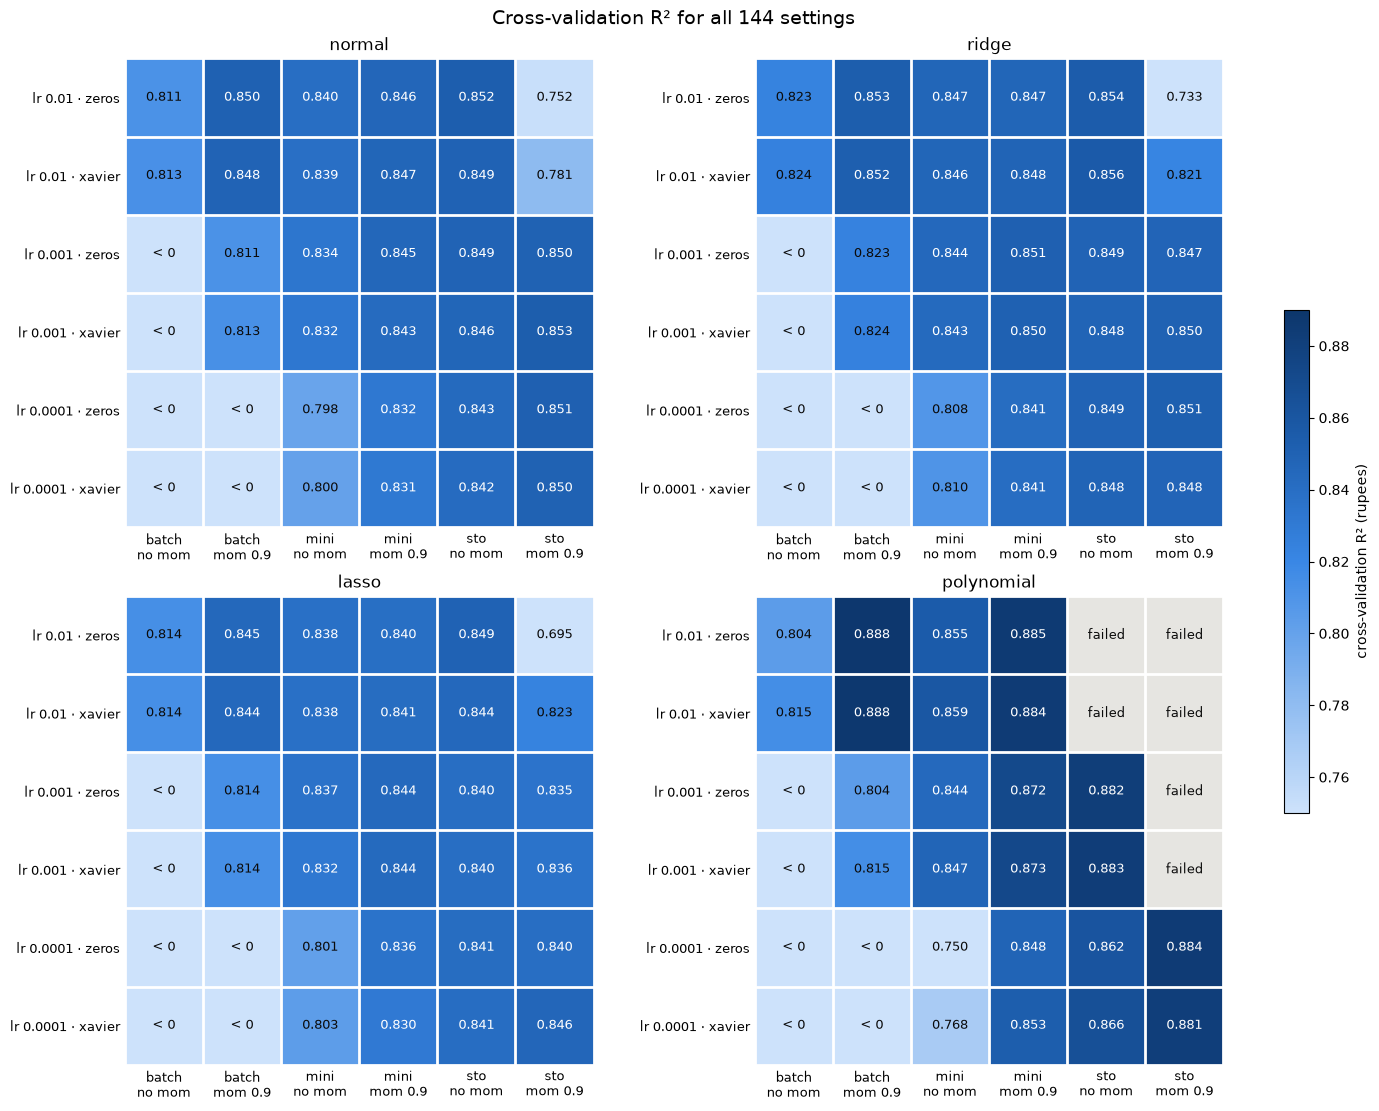

In [8]:
# Light-to-dark blue: a darker cell means a higher R²
cmap = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
cmap.set_bad('#e6e5e1')  # failed settings (no score) are grey
low, high = 0.75, 0.89  # colour range; anything lower gets the lightest blue

row_order = [(lr, init) for lr in grid['lr'] for init in grid['init']]
col_order = [(method, mom) for method in grid['method'] for mom in grid['momentum']]

fig, axes = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True)
for ax, model in zip(axes.flat, grid['model']):
    # One row per learning rate + start weights, one column per method + momentum
    table = (results[results['model'] == model]
             .set_index(['lr', 'init', 'method', 'momentum'])['cv_r2_mean']
             .unstack(['method', 'momentum'])
             .reindex(index=row_order, columns=col_order))
    values = table.to_numpy(dtype=float)
    image = ax.imshow(np.clip(values, low, high), cmap=cmap, vmin=low, vmax=high)

    # Write the score in every cell
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            v = values[i, j]
            text = 'failed' if np.isnan(v) else '< 0' if v < 0 else f'{v:.3f}'
            # White text on the darker cells so it stays readable
            color = 'white' if not np.isnan(v) and v >= 0.83 else '#0b0b0b'
            ax.text(j, i, text, ha='center', va='center', fontsize=9, color=color)

    ax.set_xticks(range(len(col_order)), [f'{m}\n{"mom 0.9" if mom else "no mom"}' for m, mom in col_order], fontsize=9)
    ax.set_yticks(range(len(row_order)), [f'lr {lr} · {init}' for lr, init in row_order], fontsize=9)
    ax.set_title(model, fontsize=12)
    ax.set_xticks(np.arange(-0.5, len(col_order)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(row_order)), minor=True)
    ax.grid(which='minor', color='white', linewidth=2) # Thin white lines between cells, no frame
    ax.tick_params(which='both', length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.colorbar(image, ax=axes, shrink=0.5, label='cross-validation R² (rupees)')
fig.suptitle('Cross-validation R² for all 144 settings', fontsize=14)
plt.show()

### Best setting for each model type

R² and MSE are both measured on the real price in rupees, averaged over the 5 folds. MSE is in rupees squared, which is hard to picture, so its square root is added as a rough "typical error" in rupees. The R² on log price is the score on the scale the models actually learn on.

In [9]:
columns = ['model', 'method', 'init', 'lr', 'momentum', 'cv_r2_mean', 'cv_r2_std', 'cv_mse_mean', 'cv_r2_log_mean', 'mean_epochs']
best_per_model = results.loc[results.groupby('model')['cv_r2_mean'].idxmax(), columns]
best_per_model = best_per_model.sort_values('cv_r2_mean', ascending=False).set_index('model')
# Square root of MSE: back in rupees, so it reads as a typical error
best_per_model['typical error (₹)'] = np.sqrt(best_per_model['cv_mse_mean'])
best_per_model.style.format({'cv_r2_mean': '{:.4f}', 'cv_r2_std': '{:.4f}', 'cv_mse_mean': '{:,.0f}',
                             'cv_r2_log_mean': '{:.4f}', 'mean_epochs': '{:,.0f}', 'typical error (₹)': '{:,.0f}', 'lr': '{:g}', 'momentum': '{:g}'})

,method,init,lr,momentum,cv_r2_mean,cv_r2_std,cv_mse_mean,cv_r2_log_mean,mean_epochs,typical error (₹)
model,,,,,,,,,,
polynomial,batch,zeros,0.01,0.9,0.8884,0.0267,"28,513,012,353",0.8933,"9,428","168,858"
ridge,sto,xavier,0.01,0,0.8561,0.0187,"36,472,249,132",0.8800,119,"190,977"
normal,sto,xavier,0.001,0.9,0.8533,0.0329,"37,490,620,273",0.8766,126,"193,625"
lasso,sto,zeros,0.01,0,0.8491,0.0181,"38,042,996,104",0.8773,97,"195,046"


### How each choice affected the score

For each of the five choices, this table groups all the settings that used a given value (for example, all 48 settings that used batch updates) and shows the best and the median cross-validation R². It also counts how many of those settings scored below 0 or failed, and the median number of epochs they trained for before stopping.

In [10]:
rows = []
for choice in grid:
    for value, group in results.groupby(choice):
        r2 = group['cv_r2_mean']
        rows.append({
            'choice': choice,
            'value': value if isinstance(value, str) else f'{value:g}',
            'settings': len(group),
            'best R²': r2.max(),
            'median R²': r2.median(),       # failed settings have no score and are skipped
            'R² below 0': int((r2 < 0).sum()),
            'failed': int(r2.isna().sum()),
            'median epochs': group['mean_epochs'].median(),
        })
choice_table = pd.DataFrame(rows).set_index(['choice', 'value'])
choice_table.style.format({'best R²': '{:.4f}', 'median R²': '{:.4f}', 'median epochs': '{:,.0f}'})

### Checking the top settings with other seeds

The best few settings are separated by tiny margins, and part of each score comes down to luck: which 10% of the training rows were held aside to decide when to stop, the random Xavier starting weights, and the order the rows were shuffled in. All of these come from one random seed (42 in the grid). To see whether the ranking holds, we run the top 5 settings again with 4 other seeds (0, 1, 2 and 3), keeping the same 5 folds. These runs are logged to MLflow too, and we pick the final setting by its average R² over all 5 seeds.

In [11]:
# The five settings with the highest cross-validation R²
top5 = results.sort_values('cv_r2_mean', ascending=False).head(5)

seed_runs = []
for _, best in top5.iterrows():
    # A grid with one value per choice is just this one setting
    one_setting = {k: [best[k]] for k in grid}
    for seed in [0, 1, 2, 3]:
        seed_runs.append(run_grid(one_setting, X_train, y_train_log, feature_columns, cv, lam=lam, seed=seed, **fixed).assign(seed=seed))

# The original seed-42 scores plus the four new seeds
all_seeds = pd.concat([top5.assign(seed=42)] + seed_runs, ignore_index=True)
all_seeds['setting'] = all_seeds.apply(run_name, axis=1)
seed_table = (all_seeds.groupby('setting', sort=False)
              .agg(r2_seed_42=('cv_r2_mean', 'first'), r2_mean=('cv_r2_mean', 'mean'),
                   r2_min=('cv_r2_mean', 'min'), r2_max=('cv_r2_mean', 'max'),
                   mse_mean=('cv_mse_mean', 'mean'), r2_log_mean=('cv_r2_log_mean', 'mean'))
              .sort_values('r2_mean', ascending=False))
seed_table.style.format({'mse_mean': '{:,.0f}'} | {c: '{:.4f}' for c in seed_table.columns if c != 'mse_mean'})         # type: ignore

[1/1] polynomial · batch · zeros · lr=0.01 · mom=0.9: already in MLflow, reused


[1/1] polynomial · batch · zeros · lr=0.01 · mom=0.9: already in MLflow, reused


[1/1] polynomial · batch · zeros · lr=0.01 · mom=0.9: already in MLflow, reused


[1/1] polynomial · batch · zeros · lr=0.01 · mom=0.9: already in MLflow, reused


[1/1] polynomial · batch · xavier · lr=0.01 · mom=0.9: already in MLflow, reused


...

[1/1] polynomial · mini · xavier · lr=0.01 · mom=0.9: already in MLflow, reused


[1/1] polynomial · mini · xavier · lr=0.01 · mom=0.9: already in MLflow, reused


[1/1] polynomial · mini · xavier · lr=0.01 · mom=0.9: already in MLflow, reused


[1/1] polynomial · mini · xavier · lr=0.01 · mom=0.9: already in MLflow, reused


,r2_seed_42,r2_mean,r2_min,r2_max,mse_mean,r2_log_mean
setting,,,,,,
polynomial · batch · xavier · lr=0.01 · mom=0.9,0.8877,0.8840,0.8676,0.8901,"29,727,980,222",0.8930
polynomial · batch · zeros · lr=0.01 · mom=0.9,0.8884,0.8833,0.8656,0.8893,"29,919,840,045",0.8929
polynomial · mini · xavier · lr=0.01 · mom=0.9,0.8841,0.8792,0.8749,0.8841,"30,973,937,715",0.8899
polynomial · mini · zeros · lr=0.01 · mom=0.9,0.8854,0.8766,0.8572,0.8873,"31,799,713,446",0.8898
polynomial · sto · zeros · lr=0.0001 · mom=0.9,0.8843,0.8710,0.8521,0.8843,"33,314,485,754",0.8908


All five settings score a little lower on average than in the grid. That is expected since they were picked for being the top 5 out of 144, so part of their lead was luck that does not repeat with other seeds. The two batch settings with momentum stay on top (average R² 0.884 and 0.883), and they differ only in the starting weights, so they are really a tie; changing the seed alone moves a setting's R² by up to about 0.03. We pick the highest average: **polynomial, batch, Xavier, learning rate 0.01, momentum 0.9**.

In [12]:
# The setting with the best average over the five seeds
best_name = seed_table.index[0]
best_setting = all_seeds.loc[all_seeds['setting'] == best_name, list(grid)].iloc[0].to_dict()
model_type = best_setting['model']
params = {k: v for k, v in best_setting.items() if k != 'model'} | fixed
best_setting

{'model': 'polynomial',
 'method': 'batch',
 'init': 'xavier',
 'lr': 0.01,
 'momentum': 0.9}

### Comparing with the earlier notebook's model on the same folds

The earlier notebook's linear regression scored about 0.86 in cross-validation, but that number was not measured in exactly the same way as the grid: that notebook filled in missing values once before splitting into folds, while here everything is learned inside each fold. To compare the two fairly, we score the earlier notebook's model (sklearn linear regression, no scaling, no degree-2 columns) on exactly the same 5 folds, with the medians learned from each fold's training rows, next to our chosen setting. The test set is still not used.

In [13]:
rows = []
for fold, (train_idx, val_idx) in enumerate(cv.split(X_train)):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train_log.iloc[train_idx], y_train_log.iloc[val_idx]

    # Earlier notebook's model: medians from this fold's training rows, no scaling
    fold_stats = fit_impute_stats(X_tr)
    old_fold = SklearnLinearRegression().fit(encode_for_model(X_tr, fold_stats, feature_columns), y_tr)
    old_log_pred = old_fold.predict(encode_for_model(X_val, fold_stats, feature_columns))

    # Our chosen setting, prepared and trained exactly as in the grid
    (X_tr_ready, X_val_ready), _ = prepare_features(X_tr, [X_val], feature_columns, polynomial=model_type == 'polynomial')
    ours_fold = build_model(model_type, lam, random_state=42, **params)
    fit_with_holdout(ours_fold, X_tr_ready, y_tr)
    new_log_pred = ours_fold.predict(X_val_ready)

    for name, log_pred in [('earlier notebook', old_log_pred), ('our model', new_log_pred)]:
        price, pred = np.exp(y_val), np.exp(log_pred)
        rows.append({'fold': fold, 'model': name, **score_rupees(y_val, log_pred),
                     'median error (%)': np.median(np.abs(pred - price) / price) * 100})

same_folds = pd.DataFrame(rows)
by_fold = same_folds.pivot(index='fold', columns='model', values='r2')
print('our model has the higher R² in', (by_fold['our model'] > by_fold['earlier notebook']).sum(), 'of', len(by_fold), 'folds')
display(by_fold.style.format('{:.4f}'))

# Averages over the 5 folds
same_summary = same_folds.groupby('model')[['r2', 'mse', 'r2_log', 'median error (%)']].mean()
same_summary.style.format({'r2': '{:.4f}', 'mse': '{:,.0f}', 'r2_log': '{:.4f}', 'median error (%)': '{:.1f}'})

our model has the higher R² in 5 of 5 folds


model,earlier notebook,our model
fold,,
0,0.7955,0.8537
1,0.8495,0.8792
2,0.8946,0.9190
3,0.8592,0.8659
4,0.8905,0.9206


,r2,mse,r2_log,median error (%)
model,,,,
earlier notebook,0.8579,"36,523,786,757",0.8824,15.7
our model,0.8877,"28,689,659,429",0.8930,14.6


Our model scores higher in every fold, with an average R² of 0.888 against 0.858, and a typical car's error drops from 15.7% to 14.6% of its price. On cars like the ones it was trained on, the degree-2 columns are a clear improvement over the earlier straight-line model.

## Final model on the test set

The chosen setting is trained once more on the whole training set, with the same early stopping rule as in cross-validation (10% of the training rows set aside to decide when to stop). The medians, scaling and degree-2 columns are learned from the training set only. Then it predicts the test set, which no step so far has touched.

For comparison, the plain linear regression from `A1_car_price_prediction.ipynb` (sklearn, no scaling, no degree-2 columns) is trained on the same training set and scored on the same test cars.

In [14]:
# Medians, one-hot columns and scaling learned from the training set, then applied to the test set
(X_train_ready, X_test_ready), final_stats = prepare_features(
    X_train, [X_test], feature_columns, polynomial=model_type == 'polynomial')
final_model = build_model(model_type, lam, random_state=42, **params)
fit_with_holdout(final_model, X_train_ready, y_train_log)
print(f'stopped after {final_model.epochs_run_} epochs, kept the weights from epoch {final_model.best_epoch_ + 1}')

# The earlier notebook's linear regression, trained on the same rows
X_test_encoded = encode_for_model(X_test, impute_stats, feature_columns)
old_model = SklearnLinearRegression().fit(X_train_encoded, y_train_log)

y_test_log = np.log(y_test)
test_pred = np.exp(final_model.predict(X_test_ready))
old_pred = np.exp(old_model.predict(X_test_encoded))
test_scores = score_rupees(y_test_log, np.log(test_pred))
old_scores = score_rupees(y_test_log, np.log(old_pred))

test_table = pd.DataFrame({
    'test R²': [test_scores['r2'], old_scores['r2']],
    'test MSE': [test_scores['mse'], old_scores['mse']],
    'typical error (₹)': [np.sqrt(test_scores['mse']), np.sqrt(old_scores['mse'])],
    'test R² (log price)': [test_scores['r2_log'], old_scores['r2_log']],
    # How far off a typical car is, in percent of its real price
    'median error (%)': [np.median(np.abs(test_pred - y_test) / y_test) * 100,
                         np.median(np.abs(old_pred - y_test) / y_test) * 100],
}, index=[f'our class: {best_name}', 'sklearn linear regression (earlier notebook)'])
test_table.style.format({'test R²': '{:.4f}', 'test MSE': '{:,.0f}', 'typical error (₹)': '{:,.0f}', 'test R² (log price)': '{:.4f}', 'median error (%)': '{:.1f}'})

stopped after 9021 epochs, kept the weights from epoch 8971


,test R²,test MSE,typical error (₹),test R² (log price),median error (%)
our class: polynomial · batch · xavier · lr=0.01 · mom=0.9,0.8349,"45,815,168,813","214,045",0.8883,14.8
sklearn linear regression (earlier notebook),0.8925,"29,843,027,000","172,751",0.8756,15.2


### Where the test errors come from

MSE squares each error, so a few very expensive cars can outweigh hundreds of ordinary ones. This table lists the test cars that make up the largest share of our model's squared error, with both models' predictions.

In [15]:
errors = X_test[['brand', 'year', 'max_power', 'engine']].assign(
    price=y_test, ours=test_pred.round(), earlier=old_pred.round())
# Each car's share of the total squared error of our model
squared = (errors['ours'] - errors['price']) ** 2
errors['share of our squared error'] = squared / squared.sum()
display(errors.sort_values('share of our squared error', ascending=False).head(5)
        .style.format({'ours': '{:,.0f}', 'earlier': '{:,.0f}', 'price': '{:,.0f}', 'max_power': '{:.0f}',
                       'engine': '{:.0f}', 'share of our squared error': '{:.1%}'}))

# The same R² in rupees with the single biggest error left out
keep = errors.index != squared.idxmax()
print(f"R² without that car: ours {score_rupees(y_test_log[keep], np.log(test_pred[keep]))['r2']:.4f}, "
      f"earlier {score_rupees(y_test_log[keep], np.log(old_pred[keep]))['r2']:.4f}")
print('most powerful car in the training set:', X_train['max_power'].max(), 'bhp')

,brand,year,max_power,engine,price,ours,earlier,share of our squared error
167,Volvo,2017,400,1969,"10,000,000","4,547,169","12,867,909",47.5%
132,Land,2019,148,1999,"4,500,000","1,986,775","4,136,820",10.1%
5266,Toyota,2014,170,2982,"3,500,000","1,627,462","1,866,162",5.6%
996,BMW,2013,241,2993,"3,750,000","2,328,387","3,189,456",3.2%
1005,Toyota,2019,172,2755,"1,925,000","3,145,737","3,490,482",2.4%


R² without that car: ours 0.8862, earlier 0.8873
most powerful car in the training set: 282.0 bhp


### Saving the final model in MLflow

The tested model is logged to MLflow as its own run, together with its test scores. It is saved as an MLflow model that takes cleaned car rows and returns prices in rupees, so the preparation steps travel with it. If this notebook is run again, the existing run is found and nothing is logged twice.

In [16]:
class CarPriceModel(mlflow.pyfunc.PythonModel):
    """Cleaned car rows in, prices in rupees out."""

    def __init__(self, model, stats):
        self.model = model
        self.stats = stats

    def predict(self, context, model_input: pd.DataFrame, params=None):
        # Same steps as in training: fill gaps, one-hot encode, scale, predict, undo the log
        encoded = encode_for_model(model_input, self.stats['impute_stats'], self.stats['feature_columns'])
        return np.exp(self.model.predict(apply_scaler(encoded, self.stats['scaler_stats'])))


earlier = mlflow.search_runs(filter_string="attributes.run_name = 'final model' and attributes.status = 'FINISHED'")
if earlier.empty:
    with mlflow.start_run(run_name='final model'):
        mlflow.log_params(best_setting | fixed | {'lam': lam if model_type in ('ridge', 'lasso') else 0.0, 'seed': 42})
        mlflow.log_metrics({'test_r2': test_scores['r2'], 'test_mse': test_scores['mse'], 'test_r2_log': test_scores['r2_log'],
                            'cv_r2_mean_5_seeds': seed_table.loc[best_name, 'r2_mean'], 'epochs_run': final_model.epochs_run_})
        with warnings.catch_warnings():
            # MLflow notes that whole-number columns can't hold missing values; 
            # but ours (year, km_driven, owner) are never missing so it's ok
            warnings.simplefilter('ignore', UserWarning)
            info = mlflow.pyfunc.log_model(
                name='model',
                python_model=CarPriceModel(final_model, final_stats),
                code_paths=['../src'],  # the model needs our src code to load
                input_example=X_test.head(3),
                pip_requirements=[f'numpy=={np.__version__}', f'pandas=={pd.__version__}'],
            )
    model_uri = info.model_uri
else:
    # Already logged by an earlier run of this notebook and we load that one
    model_uri = f"runs:/{earlier['run_id'].iloc[0]}/model"

# Load it back from MLflow and check it gives the same prices as the model in memory
loaded = mlflow.pyfunc.load_model(model_uri)
same = np.allclose(loaded.predict(X_test.head(20)), np.exp(final_model.predict(X_test_ready.head(20))))
print(model_uri, '| same predictions after loading:', same)

runs:/d544279d6ed14354a3d6472152bc3c9f/model | same predictions after loading: True


## Feature importance

Below is the chart from the class's `plot_feature_importance` function, showing the 20 biggest coefficients of the final model. Comparing sizes is fair here because every number column (and every degree-2 column) was scaled to the same spread before training, and the yes/no columns are all 0 or 1.

The brand bars need care, for the same reason as in `A1_car_price_prediction.ipynb`. Turning brand into yes/no columns leaves one brand out as the baseline that every other brand is compared against, and here that is Ambassador, a brand with only 2 cars in the training data. So each brand bar means "this brand compared with an Ambassador", which is why almost every brand looks like it raises the price. The second chart (similar process as in our earlier notebook) redoes the comparison against Maruti, the most common brand, and leaves out the brands with 11 or fewer cars in the training data. This only changes which brand everything is compared against; the model and its predictions stay the same.

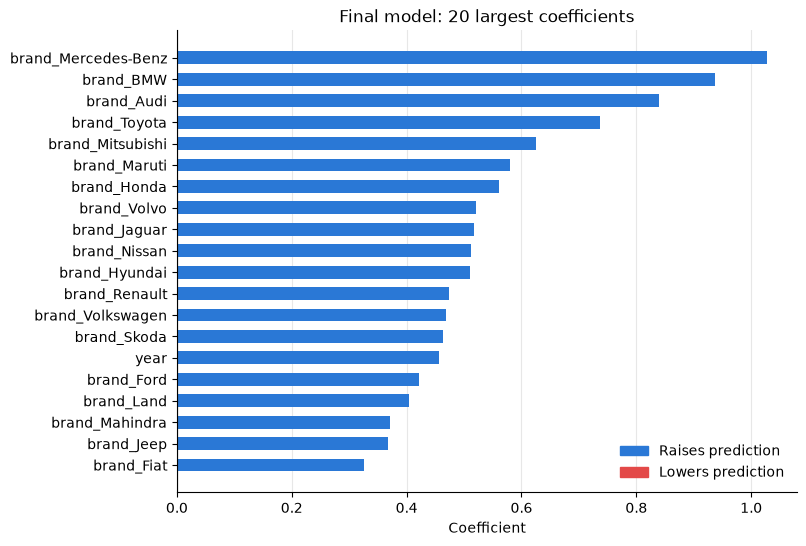

In [17]:
ax = final_model.plot_feature_importance(list(X_train_ready.columns), top_n=20)
ax.set_title('Final model: 20 largest coefficients')
plt.show()

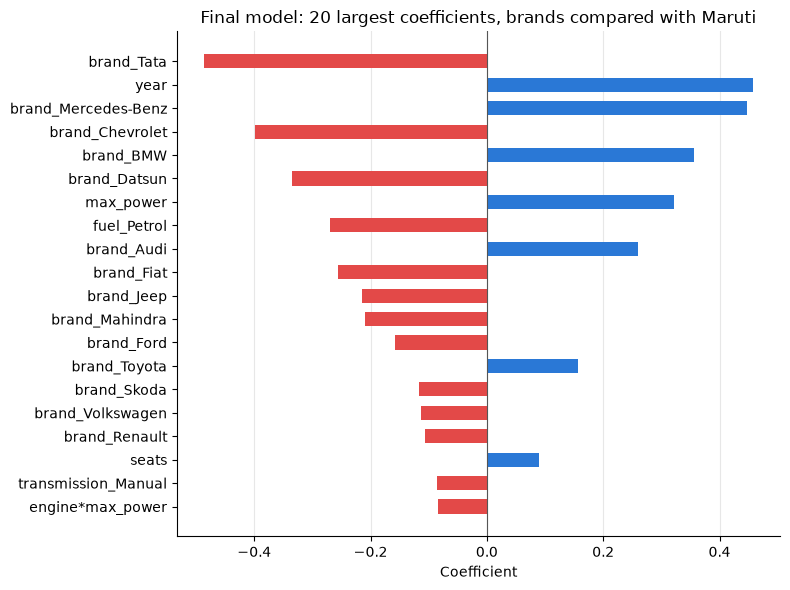

In [18]:
coef = pd.Series(final_model.coef_, index=X_train_ready.columns)
brand_cols = [c for c in coef.index if c.startswith('brand_')]

# Measure every brand against Maruti instead of Ambassador
relative = coef.copy()
relative[brand_cols] = coef[brand_cols] - coef['brand_Maruti']
relative['brand_Ambassador'] = -coef['brand_Maruti']  # the old baseline, now shown like any other brand
relative = relative.drop(index='brand_Maruti')

# Leave out brands with 11 or fewer cars in training since they are too few to trust their weight anyway
rare = [f'brand_{b}' for b, n in X_train['brand'].value_counts().items() if n <= 11]
relative = relative.drop(index=rare, errors='ignore')
top = relative.reindex(relative.abs().sort_values(ascending=False).index[:20])[::-1]

# Same colours as the class's chart
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=['#2a78d6' if v > 0 else '#e34948' for v in top.values], height=0.6)
ax.axvline(0, color='#555555', linewidth=0.8)
ax.set_xlabel('Coefficient')
ax.set_title('Final model: 20 largest coefficients, brands compared with Maruti')
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## MLflow screenshots

Every run is in the MLflow experiment `st127634-a2`: one run per setting (144 from the grid and 20 from the seed check), with its 5 folds nested inside, plus one run for the final model.

**All settings, sorted by cross-validation R².** Each row is one setting from the grid, and its scores are the averages over its 5 folds.

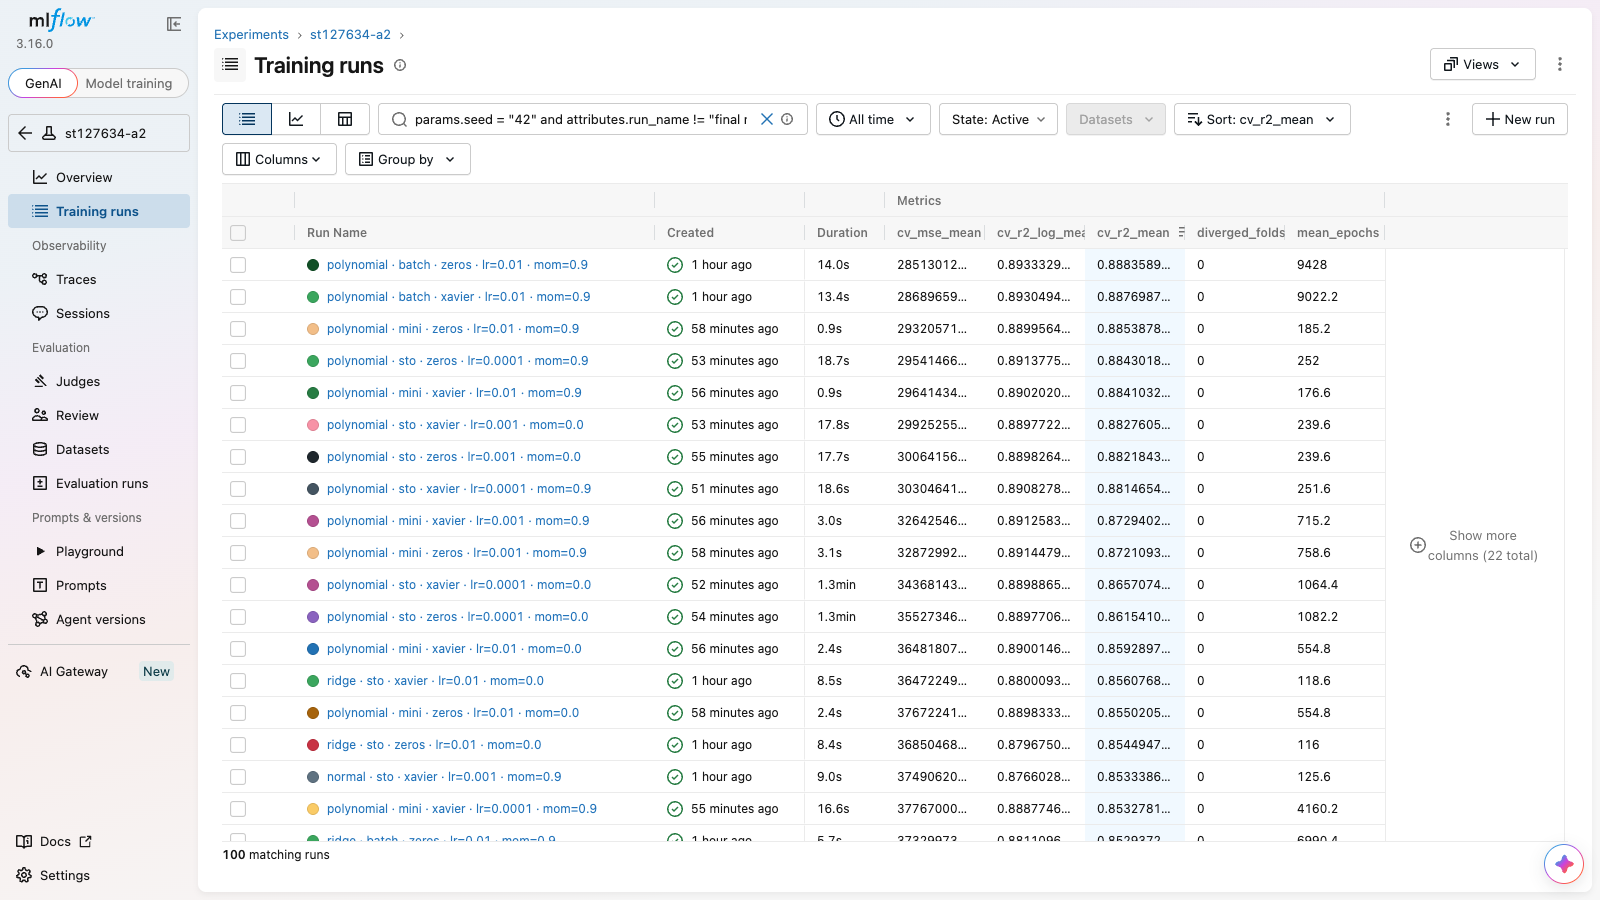

**Loss curves for one fold of the chosen setting**, on a log scale. Both the training loss and the loss on the 10% of rows set aside for early stopping drop quickly in the first thousand or so epochs and then flatten out. Training stopped once the set-aside loss had not improved for 50 epochs.

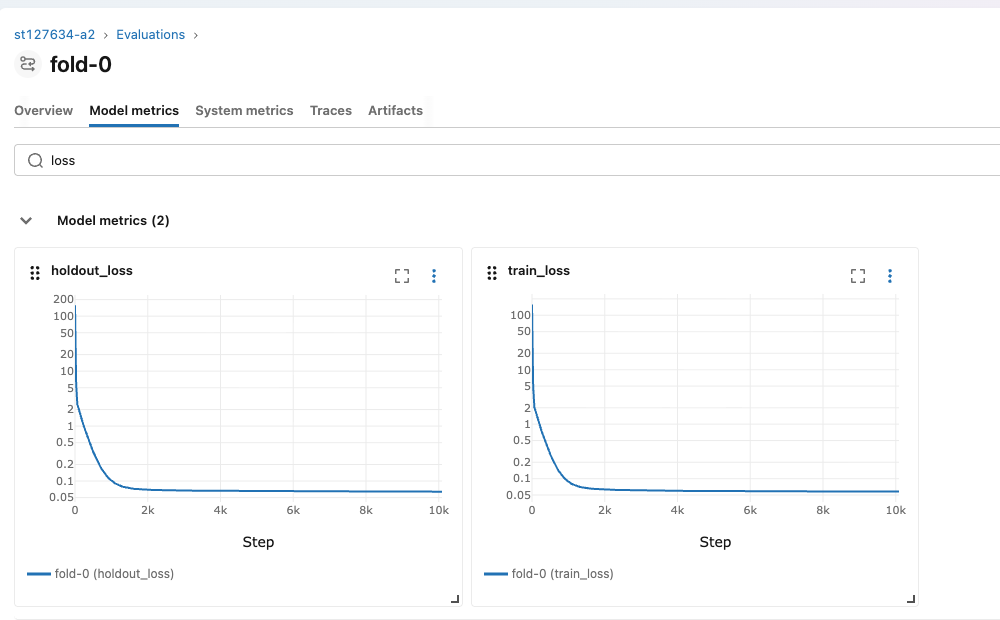

**The final model's run**, with its test scores, its setting and the saved MLflow model.

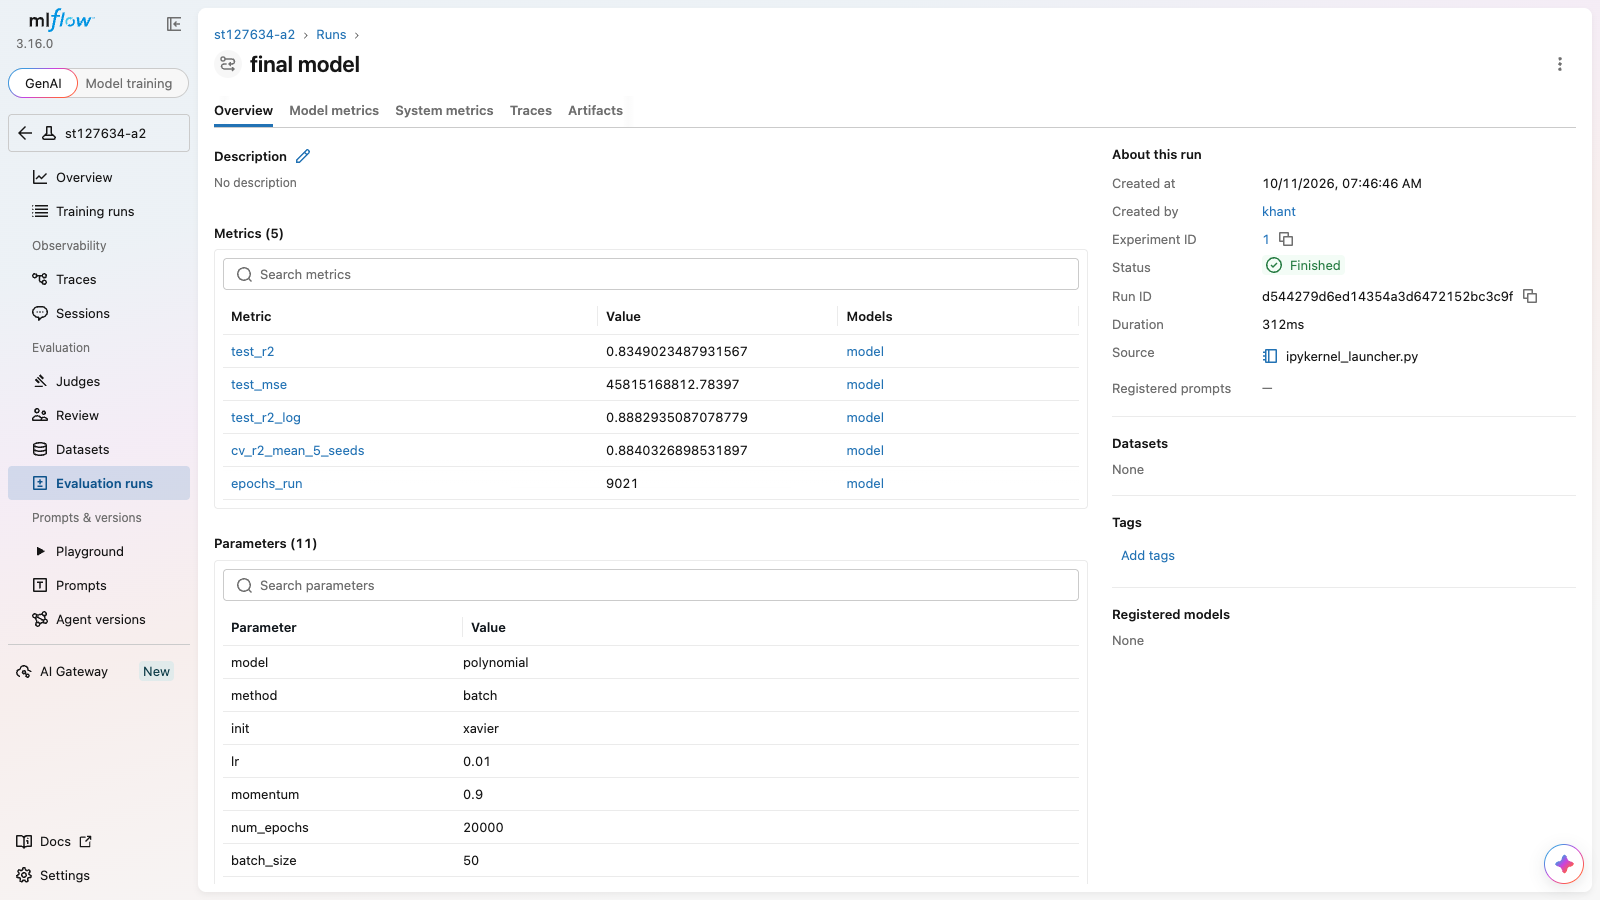

## Report

We compared 144 ways of training our own linear regression class, crossing five choices: the model type, the update method, the starting weights, the learning rate and momentum. The clearest result is that the degree-2 columns help. The best polynomial setting reached a cross-validation R² of 0.888 (0.884 averaged over five seeds), while the best normal, ridge and lasso settings all landed between 0.849 and 0.856. Scored on exactly the same folds, the earlier notebook's linear regression gets 0.858: our normal, ridge and lasso models match it, as expected from the same kind of model, and the polynomial model beats it in every fold. Squared and multiplied columns let the model bend instead of following one straight line, for example letting the effect of extra power depend on the size of the engine. Ridge and lasso barely differ from the normal model. With λ = 0.001 the penalty is small next to the error, so it only nudges the weights and it neither helps nor hurts here.

How the model is trained mattered more than the penalty. Batch updates take one step per pass over the data, so with small learning rates they were still far from a good answer when they hit the 20,000-epoch limit: all 24 settings that scored below 0 are batch runs (every batch run at 0.0001, and those at 0.001 without momentum). Momentum fixes much of this, because it lets the steps build up speed while they keep pointing the same way, and batch at learning rate 0.01 with momentum ended up as the best setting overall, though it still needed around 9,000 epochs. Mini-batch and stochastic updates take many steps per pass, so they needed far fewer epochs (a median of about 2,300 for mini-batch and 170 for stochastic, against the full 20,000 for batch). For stochastic updates, momentum did the opposite at the largest learning rate: each step is based on one car, so steps are noisy, and momentum makes each one up to about 10 times bigger. That lowered the normal, ridge and lasso scores to between 0.70 and 0.82, and made 6 polynomial settings blow up completely. Starting from zeros or from Xavier made no real difference (median R² 0.8398 against 0.8397). For linear regression the loss has a single lowest point, like the bottom of a bowl, so every starting point ends up in the same place, and Xavier's small random start values only change the path a little.

On the test set the result is mixed. Measured on log price, where every car counts the same, the new model beats the earlier notebook's linear regression (R² 0.888 against 0.876), and its median error is slightly smaller (14.8% against 15.2% of the real price). Measured in rupees it does worse (R² 0.835 against 0.893). The table in "Where the test errors come from" shows why: one car, a 2017 Volvo listed at ₹10,000,000 with 400 bhp, makes up 47.5% of our model's squared error. No car in the training set has more than 282 bhp, so both models are guessing beyond anything they have seen. The straight-line model keeps adding the same percentage of price for every extra bhp and lands at ₹12.9M, while the polynomial model's curve flattens out at high power and lands at ₹4.5M. Without that one car, the two models score the same in rupees (0.886 against 0.887). Cross-validation never had to price a car like this, because none of the training cars is that powerful, which is why it and the test set disagree. So the new model is better for cars like the ones it was trained on, as cross-validation shows, but less safe for unusual, very powerful cars.

The feature importance charts tell the same story as before. Newer cars and more power raise the price the most, petrol and manual cars sell for less, and among brands Mercedes-Benz, BMW and Audi sell for more than Maruti, while Tata, Chevrolet and Datsun sell for less. Only one degree-2 column (engine × max_power) makes the top 20 in the second chart, which fits the gain from the polynomial model being real but modest.

### Final comparison table

The best setting of each model type from the grid (cross-validation, seed 42), the final model (cross-validation averaged over five seeds, then the test set), and the earlier notebook's linear regression (cross-validation on the same 5 folds, then the same test set). R² and MSE are on the real price in rupees unless marked as log price.

In [19]:
final_rows = [{'model': model, 'setting': run_name({'model': model, **r}),
               'CV R²': r['cv_r2_mean'], 'CV MSE': r['cv_mse_mean']}
              for model, r in best_per_model.iterrows()]
final_rows.append({'model': 'final model', 'setting': f'{best_name} (5-seed average)',
                   'CV R²': seed_table.loc[best_name, 'r2_mean'], 'CV MSE': seed_table.loc[best_name, 'mse_mean'],
                   'test R²': test_scores['r2'], 'test MSE': test_scores['mse'], 'test R² (log price)': test_scores['r2_log']})
final_rows.append({'model': 'earlier notebook', 'setting': 'sklearn linear regression',
                   'CV R²': same_summary.loc['earlier notebook', 'r2'], 'CV MSE': same_summary.loc['earlier notebook', 'mse'],
                   'test R²': old_scores['r2'], 'test MSE': old_scores['mse'], 'test R² (log price)': old_scores['r2_log']})

final_table = pd.DataFrame(final_rows).set_index('model')
final_table.style.format({'CV R²': '{:.4f}', 'CV MSE': '{:,.0f}', 'test R²': '{:.4f}', 'test MSE': '{:,.0f}',
                          'test R² (log price)': '{:.4f}'}, na_rep='–')

,setting,CV R²,CV MSE,test R²,test MSE,test R² (log price)
model,,,,,,
polynomial,polynomial · batch · zeros · lr=0.01 · mom=0.9,0.8884,"28,513,012,353",–,–,–
ridge,ridge · sto · xavier · lr=0.01 · mom=0.0,0.8561,"36,472,249,132",–,–,–
normal,normal · sto · xavier · lr=0.001 · mom=0.9,0.8533,"37,490,620,273",–,–,–
lasso,lasso · sto · zeros · lr=0.01 · mom=0.0,0.8491,"38,042,996,104",–,–,–
final model,polynomial · batch · xavier · lr=0.01 · mom=0.9 (5-seed average),0.8840,"29,727,980,222",0.8349,"45,815,168,813",0.8883
earlier notebook,sklearn linear regression,0.8579,"36,523,786,757",0.8925,"29,843,027,000",0.8756


## Limitations and design decisions

This section gathers the limitations of the experiment and of the chosen model. The limitations of the data itself (how missing values are filled in, brands with very few cars, and the model being unreliable for cars made before 2000) are covered in `A1_car_price_prediction.ipynb` and still apply here, because the cleaning and the train/test split are the same.

### The new model should not be trusted for very powerful cars

The most powerful car in the training set has 282 bhp. Past that point any model is guessing, and the two models guess differently. The straight-line model from the earlier notebook adds the same percentage of price for every extra bhp, while our model's degree-2 columns (such as engine × max_power and max_power²) bend the curve, and at very high power that bend points downward. For the 400 bhp Volvo in the test set, the straight-line model predicted ₹12.9M and ours predicted ₹4.5M, against a real price of ₹10M. That one car is about half of our model's squared error on the test set and the whole reason its rupee R² is lower than the earlier model's. The curve is fitted to the cars it has seen, so it works inside that range and can bend the wrong way outside it. Predictions for cars above roughly 280 bhp should be treated as rough guesses. One way to make the curve safer would be to cap each number at the training range before building the degree-2 columns. We did not try this, because the idea came after looking at the test set, and changing the model because of the test set would mean its test score is no longer an honest check.

### Small differences in R² are mostly noise

Part of every score comes down to luck: which rows were set aside for early stopping, the Xavier starting weights and the shuffle order. Running the top 5 settings again with other seeds moved their R² in rupees by up to about 0.03, while their R² on log price moved by less than 0.004. The rupee score is much jumpier because errors on the few very expensive cars become huge once prices are turned back into rupees and squared, so a handful of cars can swing it. Because of this, we treat settings within about 0.03 of each other as tied, and picked the final setting by its average over five seeds instead of by one lucky run. The top two settings (batch with momentum, starting from zeros or from Xavier) are really a tie.

### λ was fixed, not tuned

Ridge and lasso use one penalty strength, λ = 0.001, in every setting, because the assignment asks us to compare the model types rather than tune each one. We picked this value with a quick check on the training data before the experiment (not shown here). Stronger penalties lowered R² noticeably, and at λ = 0.1 lasso kept only 3 of the 41 weights. At 0.001 the penalty is small, so ridge and lasso end up almost the same as the normal model. This means the comparison only tells us that a mild penalty neither helps nor hurts on this data, not how ridge and lasso would do with a stronger one.

### Only degree 2 was tried

The polynomial model uses degree 2 (every number column squared and every pair multiplied), the same as the example from the lecture notebook, and we did not compare it with higher degrees. Degree 2 is the simplest curve, and it already adds 28 columns to the 41. Degree 3 would add 84 more, giving gradient descent many more weights to learn from the same 5,461 cars, making the very large values that already break stochastic updates even larger, and bending even harder outside the range of the training data. Like λ, the degree was fixed instead of tuning it.

### Every setting had the same training budget

Every setting could train for at most 20,000 epochs, and stopped earlier once the loss on 10% of its training rows had not improved for 50 epochs. Batch updates with small learning rates (0.0001, or 0.001 without momentum) used up all 20,000 epochs while still far from a good answer, which is why they score below 0. Their scores show what they reach within this budget, not the best they could ever do: every setting is lowering the same loss, so with enough epochs they would end up in the same place as the others. Also, because 10% of the rows are kept aside to decide when to stop, each model only trains on 90% of the rows it is given.

### Some settings failed and were left as failed

Six polynomial settings with stochastic updates blew up within the first few epochs: all four at learning rate 0.01, and both at 0.001 with momentum (momentum makes each step up to about 10 times bigger, so these behave like a learning rate of 0.01). Some degree-2 columns have a few very large values even after scaling, such as km_driven² for cars with very high mileage, and a single step on one of those cars at a large step size throws the weights far off. We count a run as failed as soon as its training loss is higher than it was before training started. We left these settings as failures instead of adding a fix such as capping the step size, because that would change the method being compared. Stochastic updates with smaller learning rates work fine (the best one reached 0.884).

### Brand weights depend on a brand with two cars

Turning brand into yes/no columns leaves one brand out as the baseline, and here that is Ambassador, which has only 2 cars in the training data. For the normal and polynomial models nothing holds the brand weights in place, so they keep drifting slowly together for as long as training runs (the sklearn check near the top of this notebook shows the same thing). Predictions for common brands are not affected, because the drift cancels out against the intercept, but the raw brand coefficients are hard to read. This is why the second feature importance chart compares brands with Maruti and leaves out brands with 11 or fewer cars.

## Final model for the app

The model used by the app is trained once more on all 6,827 cleaned cars, with the chosen setting and the same early stopping rule (10% of the rows set aside to decide when to stop). The medians, the one-hot columns and the scaling are all learned again from the full data, so brands that were only in the test set (Ashok) now get their own column.

The saved file holds the model and everything needed to prepare a new car the same way it was prepared in training: the medians for filling gaps, the column list and the scaling numbers. It also stores the same lists of choices as the first model's file (brands, fuel types and so on), the chosen setting, and the cross-validation and test scores above, so the app page can show how the two models compare.

In [20]:
X_full = df_clean.drop(columns=['selling_price'])
y_full_log = np.log(df_clean['selling_price'])

# Column list from all cars, so brands seen only in the test set get a column too
full_columns = list(encode_for_model(X_full, fit_impute_stats(X_full)).columns)
(X_full_ready,), app_stats = prepare_features(X_full, [], full_columns, polynomial=model_type == 'polynomial')
app_model = build_model(model_type, lam, random_state=42, **params)
fit_with_holdout(app_model, X_full_ready, y_full_log)
print(f'{len(full_columns)} columns, {X_full_ready.shape[1]} with the degree-2 terms; '
      f'stopped after {app_model.epochs_run_} epochs')

# Plain Python numbers, so the file does not depend on numpy number types
setting = {k: v if isinstance(v, str) else float(v) for k, v in best_setting.items()}
scores = {
    'cv_r2_mean_5_seeds': seed_table.loc[best_name, 'r2_mean'],
    'cv_mse_mean_5_seeds': seed_table.loc[best_name, 'mse_mean'],
    'test_r2': test_scores['r2'], 'test_mse': test_scores['mse'], 'test_r2_log': test_scores['r2_log'],
    'old_test_r2': old_scores['r2'], 'old_test_mse': old_scores['mse'], 'old_test_r2_log': old_scores['r2_log'],
    'test_median_error_pct': test_table.iloc[0]['median error (%)'],
    'old_test_median_error_pct': test_table.iloc[1]['median error (%)'],
    'same_folds_r2': same_summary.loc['our model', 'r2'],
    'same_folds_median_error_pct': same_summary.loc['our model', 'median error (%)'],
    'old_same_folds_r2': same_summary.loc['earlier notebook', 'r2'],
    'old_same_folds_median_error_pct': same_summary.loc['earlier notebook', 'median error (%)'],
}

joblib.dump(
    {
        'model': app_model,
        'impute_stats': app_stats['impute_stats'],
        'scaler_stats': app_stats['scaler_stats'],
        'feature_columns': app_stats['feature_columns'],
        'setting': setting | fixed | {'lam': lam if model_type in ('ridge', 'lasso') else 0.0},
        'scores': {k: float(v) for k, v in scores.items()},
        'fuel_options': sorted(X_full['fuel'].unique()),
        'seller_type_options': sorted(X_full['seller_type'].unique()),
        'transmission_options': sorted(X_full['transmission'].unique()),
        'brand_options': sorted(X_full['brand'].unique()),
        'seats_options': sorted(int(s) for s in X_full['seats'].dropna().unique()),
        'year_min': int(X_full['year'].min()),
        'year_max': int(X_full['year'].max()),
        'km_driven_min': int(X_full['km_driven'].min()),
        'km_driven_max': int(X_full['km_driven'].max()),
        'mileage_min': float(X_full['mileage'].min()),
        'mileage_max': float(X_full['mileage'].max()),
        'engine_min': float(X_full['engine'].min()),
        'engine_max': float(X_full['engine'].max()),
        'max_power_min': float(X_full['max_power'].min()),
        'max_power_max': float(X_full['max_power'].max()),
    },
    '../app/code/models/custom_model.joblib',
)

42 columns, 70 with the degree-2 terms; stopped after 6107 epochs


['../app/code/models/custom_model.joblib']